In [147]:
%pip install -q segmentation-models-pytorch
%pip install -q torchinfo
%pip install -q albumentations

^C
ERROR: Operation cancelled by user
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


# 1. Imports & Configuration

In [148]:

import os
import random
import numpy as np
import matplotlib.pyplot as plt
import cv2

import torch
import torch.nn as nn
import segmentation_models_pytorch as smp
from torch.utils.data import Dataset, DataLoader 
from torchinfo import summary


from tqdm.auto import tqdm
from pathlib import Path
import albumentations as A



# Configuration
IMG_SIZE = 256
BATCH_SIZE = 16
EPOCHS = 40
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4
MIN_DELTA = 0.001
PATIENCE = 7
THRESHOLD = 0.5
CHECKPOINT_PATH = "best_resnet_unet.pth"

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Device:", DEVICE)


print("PyTorch:", torch.__version__)
print("GPU Available:", torch.cuda.is_available())


Device: cuda
PyTorch: 2.11.0+cu130
GPU Available: True


# 2. Dataset Loading & EDA 

In [149]:

DATA_DIR = Path("/kaggle/input")

for folder in DATA_DIR.iterdir():
    print("Dataset:", folder.name)

    for path in list(folder.rglob("*"))[:20]:
        print(" ", path.relative_to(folder))


Dataset: datasets
  farzadnekouei
  farzadnekouei/pothole-image-segmentation-dataset
  farzadnekouei/pothole-image-segmentation-dataset/Pothole_Segmentation_YOLOv8
  farzadnekouei/pothole-image-segmentation-dataset/Pothole_Segmentation_YOLOv8/README.dataset.txt
  farzadnekouei/pothole-image-segmentation-dataset/Pothole_Segmentation_YOLOv8/README.roboflow.txt
  farzadnekouei/pothole-image-segmentation-dataset/Pothole_Segmentation_YOLOv8/data.yaml
  farzadnekouei/pothole-image-segmentation-dataset/Pothole_Segmentation_YOLOv8/sample_video.mp4
  farzadnekouei/pothole-image-segmentation-dataset/Pothole_Segmentation_YOLOv8/train
  farzadnekouei/pothole-image-segmentation-dataset/Pothole_Segmentation_YOLOv8/valid
  farzadnekouei/pothole-image-segmentation-dataset/Pothole_Segmentation_YOLOv8/train/images
  farzadnekouei/pothole-image-segmentation-dataset/Pothole_Segmentation_YOLOv8/train/labels
  farzadnekouei/pothole-image-segmentation-dataset/Pothole_Segmentation_YOLOv8/valid/images
  farzad

In [150]:

DATASET_PATH = (
    DATA_DIR
    / "datasets"
    / "farzadnekouei"
    / "pothole-image-segmentation-dataset"
    / "Pothole_Segmentation_YOLOv8"
)

TRAIN_IMAGES = DATASET_PATH / "train/images"
TRAIN_LABELS = DATASET_PATH / "train/labels"

VALID_IMAGES = DATASET_PATH / "valid/images"
VALID_LABELS = DATASET_PATH / "valid/labels"

print("Dataset exists:", DATASET_PATH.exists())
print("Train images:", TRAIN_IMAGES.exists())
print("Train labels:", TRAIN_LABELS.exists())
print("Valid images:", VALID_IMAGES.exists())
print("Valid labels:", VALID_LABELS.exists())


Dataset exists: True
Train images: True
Train labels: True
Valid images: True
Valid labels: True


In [151]:

def get_images(folder):
    extensions = {".jpg", ".jpeg", ".png"}
    return sorted(
        p for p in folder.iterdir()
        if p.suffix.lower() in extensions
    )

train_images = get_images(TRAIN_IMAGES)
valid_images = get_images(VALID_IMAGES)

train_labels = list(TRAIN_LABELS.glob("*.txt"))
valid_labels = list(VALID_LABELS.glob("*.txt"))

print("Train Images:", len(train_images))
print("Train Labels:", len(train_labels))
print("Valid Images:", len(valid_images))
print("Valid Labels:", len(valid_labels))


Train Images: 720
Train Labels: 720
Valid Images: 60
Valid Labels: 60


In [152]:

def yolo_to_mask(label_path, height, width):

    mask = np.zeros((height, width), dtype=np.uint8)

    if not label_path.exists():
        return mask

    with open(label_path, "r") as f:
        lines = f.readlines()

    for line in lines:
        values = list(map(float, line.strip().split()))

        if len(values) < 7:
            continue

        points = np.array(values[1:]).reshape(-1, 2)

        points[:, 0] *= width
        points[:, 1] *= height

        points = points.astype(np.int32)

        cv2.fillPoly(mask, [points], 1)

    return mask


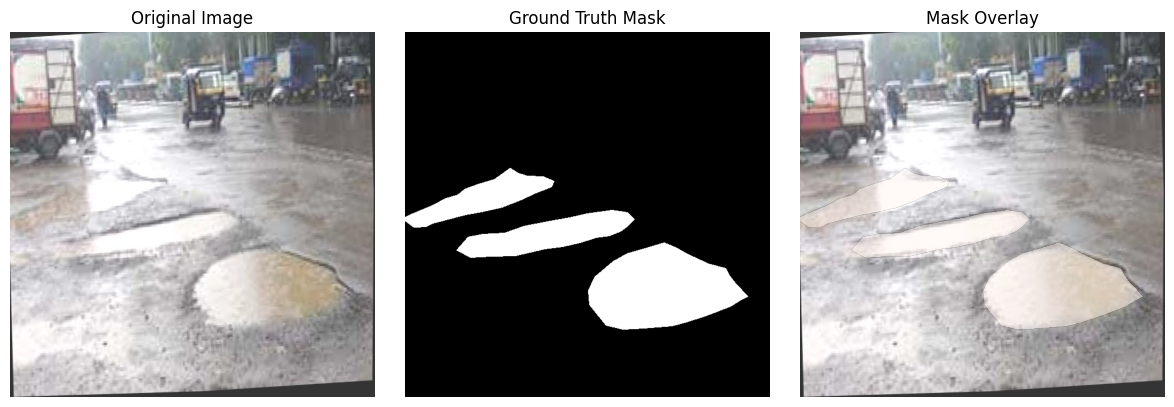

In [153]:

image_path = train_images[0]

label_path = TRAIN_LABELS / (
    image_path.stem + ".txt"
)

image = cv2.imread(str(image_path))
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

height, width = image.shape[:2]

mask = yolo_to_mask(label_path, height, width)

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(mask, cmap="gray")
plt.title("Ground Truth Mask")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(image)
plt.imshow(
    np.ma.masked_where(mask == 0, mask),
    cmap="Reds",
    alpha=0.5
)
plt.title("Mask Overlay")
plt.axis("off")

plt.tight_layout()
plt.show()


In [154]:

samples = random.sample(
    train_images,
    min(4, len(train_images))
)

fig, axes = plt.subplots(
    len(samples), 2,
    figsize=(10, 4 * len(samples)),
    squeeze=False
)

for i, image_path in enumerate(samples):

    image = cv2.imread(str(image_path))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    h, w = image.shape[:2]

    label_path = TRAIN_LABELS / (
        image_path.stem + ".txt"
    )

    mask = yolo_to_mask(label_path, h, w)

    axes[i, 0].imshow(image)
    axes[i, 0].set_title("Road Image")
    axes[i, 0].axis("off")

    axes[i, 1].imshow(mask, cmap="gray")
    axes[i, 1].set_title("Pothole Mask")
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()


KeyboardInterrupt: 

In [ ]:

pothole_ratios = []

for image_path in train_images:

    image = cv2.imread(str(image_path))

    if image is None:
        continue

    h, w = image.shape[:2]

    label_path = TRAIN_LABELS / (
        image_path.stem + ".txt"
    )

    mask = yolo_to_mask(label_path, h, w)

    ratio = mask.mean() * 100
    pothole_ratios.append(ratio)

plt.figure(figsize=(8, 4))
plt.hist(pothole_ratios, bins=20)

plt.title("Pothole Pixel Distribution")
plt.xlabel("Pothole Area (%)")
plt.ylabel("Number of Images")

plt.show()

print(
    "Average Pothole Coverage:",
    round(np.mean(pothole_ratios), 2),
    "%"
)


# 3. Create PyTorch Dataset

In [ ]:

train_transform = A.Compose([
    A.HorizontalFlip(p=0.5),

    A.Affine(
        scale=(0.9, 1.1),
        translate_percent=(-0.05, 0.05),
        rotate=(-10, 10),
        p=0.5
    ),

    A.RandomBrightnessContrast(
        brightness_limit=0.2,
        contrast_limit=0.2,
        p=0.5
    ),

    A.GaussNoise(p=0.2),

    A.GaussianBlur(
        blur_limit=(3, 5),
        p=0.2
    ),

    A.Resize(
        height=IMAGE_SIZE,
        width=IMAGE_SIZE
    )
])

valid_transform = A.Compose([
    A.Resize(
        height=IMAGE_SIZE,
        width=IMAGE_SIZE
    )
])


In [ ]:

class PotholeDataset(Dataset):

    def __init__(self, image_paths, labels_dir, transform=None):
        self.image_paths = image_paths
        self.labels_dir = labels_dir
        self.transform = transform

        # ImageNet normalization
        self.mean = np.array(
            [0.485, 0.456, 0.406], dtype=np.float32
        )
        self.std = np.array(
            [0.229, 0.224, 0.225], dtype=np.float32
        )

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):

        image_path = self.image_paths[idx]

        # Load RGB image
        image = cv2.imread(str(image_path))

        if image is None:
            raise ValueError(f"Cannot read image: {image_path}")

        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        h, w = image.shape[:2]

        # Convert YOLO polygons to binary mask
        label_path = self.labels_dir / (image_path.stem + ".txt")
        mask = yolo_to_mask(label_path, h, w)

        # Apply augmentations
        if self.transform is not None:
            augmented = self.transform(image=image, mask=mask)
            image = augmented["image"]
            mask = augmented["mask"]

        # Normalize using ImageNet statistics
        image = image.astype(np.float32) / 255.0
        image = (image - self.mean) / self.std

        # Convert image to tensor [3, H, W]
        image = torch.from_numpy(
            image.transpose(2, 0, 1).copy()
        ).float()

        # Convert mask to tensor [1, H, W]
        mask = torch.from_numpy(
            (mask > 0).astype(np.float32)
        ).unsqueeze(0)

        return image, mask


In [ ]:

train_dataset = PotholeDataset(
    train_images,
    TRAIN_LABELS,
    transform=train_transform
)

valid_dataset = PotholeDataset(
    valid_images,
    VALID_LABELS,
    transform=valid_transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=(DEVICE == "cuda")
)

valid_loader = DataLoader(
    valid_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=(DEVICE == "cuda")
)

print("Train Samples:", len(train_dataset))
print("Validation Samples:", len(valid_dataset))


In [ ]:

# ImageNet normalization statistics
mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

fig, axes = plt.subplots(3, 3, figsize=(12, 12))

for i in range(3):

    image, mask = train_dataset[
        random.randrange(len(train_dataset))
    ]

    # Convert tensor to NumPy
    img = image.permute(1, 2, 0).cpu().numpy()
    mask = mask.squeeze().cpu().numpy()

    # Denormalize image
    img = np.clip(img * std + mean, 0, 1)

    # Augmented Image
    axes[i, 0].imshow(img)
    axes[i, 0].set_title("Augmented Road Image")

    # Ground Truth Mask
    axes[i, 1].imshow(
        mask, cmap="gray", vmin=0, vmax=1
    )
    axes[i, 1].set_title("Ground Truth Mask")

    # Mask Overlay
    axes[i, 2].imshow(img)
    axes[i, 2].imshow(
        np.ma.masked_where(mask == 0, mask),
        cmap="Reds",
        alpha=0.5,
        vmin=0,
        vmax=1
    )
    axes[i, 2].set_title("Pothole Mask Overlay")

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()


In [ ]:

images, masks = next(iter(train_loader))

print("Images:", images.shape)
print("Masks:", masks.shape)
print("Mask Values:", torch.unique(masks))


# 4. Build U-net Model 

In [170]:

model = smp.Unet(
    encoder_name="resnet101",
    encoder_weights="imagenet",
    in_channels=3,
    classes=1,
    activation=None
).to(DEVICE)

print("U-Net with ResNet101 created!")


config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  179MB            

model.safetensors: downloading bytes:           |  0.00B            

U-Net with ResNet101 created!


In [171]:
print("Model Summary:\n")

summary(
    model,
    input_size=(1, 3, IMAGE_SIZE, IMAGE_SIZE),
    device=DEVICE,
    col_names=[
        "input_size",
        "output_size",
        "num_params"
    ],
    depth=3
)

Model Summary:



Layer (type:depth-idx)                        Input Shape               Output Shape              Param #
Unet                                          [1, 3, 256, 256]          [1, 1, 256, 256]          --
├─ResNetEncoder: 1-1                          [1, 3, 256, 256]          [1, 3, 256, 256]          --
│    └─Conv2d: 2-1                            [1, 3, 256, 256]          [1, 64, 128, 128]         9,408
│    └─BatchNorm2d: 2-2                       [1, 64, 128, 128]         [1, 64, 128, 128]         128
│    └─ReLU: 2-3                              [1, 64, 128, 128]         [1, 64, 128, 128]         --
│    └─MaxPool2d: 2-4                         [1, 64, 128, 128]         [1, 64, 64, 64]           --
│    └─Sequential: 2-5                        [1, 64, 64, 64]           [1, 256, 64, 64]          --
│    │    └─Bottleneck: 3-1                   [1, 64, 64, 64]           [1, 256, 64, 64]          75,008
│    │    └─Bottleneck: 3-2                   [1, 256, 64, 64]          [1, 25

In [172]:
class DiceLoss(nn.Module):

    def __init__(self, smooth=1.0):
        super().__init__()
        self.smooth = smooth

    def forward(self, logits, targets):

        probs = torch.sigmoid(logits)

        dims = (1, 2, 3)

        intersection = (probs * targets).sum(dim=dims)

        denominator = (
            probs.sum(dim=dims) +
            targets.sum(dim=dims)
        )

        dice = (
            2 * intersection + self.smooth
        ) / (denominator + self.smooth)

        return 1 - dice.mean()


class BCEDiceLoss(nn.Module):

    def __init__(self, bce_weight=0.5):
        super().__init__()

        self.bce = nn.BCEWithLogitsLoss()
        self.dice = DiceLoss()
        self.bce_weight = bce_weight

    def forward(self, logits, targets):

        bce_loss = self.bce(logits, targets)
        dice_loss = self.dice(logits, targets)

        return (
            self.bce_weight * bce_loss +
            (1 - self.bce_weight) * dice_loss
        )


criterion = BCEDiceLoss(bce_weight=0.5)

In [173]:
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=3,
    min_lr=1e-6
)

In [174]:
@torch.no_grad()
def calculate_metrics(logits, targets, threshold=0.5):

    probs = torch.sigmoid(logits)
    preds = (probs > threshold).float()

    dims = (1, 2, 3)
    eps = 1e-7

    intersection = (preds * targets).sum(dim=dims)

    pred_sum = preds.sum(dim=dims)
    target_sum = targets.sum(dim=dims)

    dice = (
        2 * intersection + eps
    ) / (pred_sum + target_sum + eps)

    union = pred_sum + target_sum - intersection

    iou = (
        intersection + eps
    ) / (union + eps)

    return dice.mean().item(), iou.mean().item()

In [175]:
from contextlib import nullcontext

USE_AMP = DEVICE.type == "cuda"

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=USE_AMP
)

def run_epoch(model, loader, criterion, optimizer=None):

    is_train = optimizer is not None

    model.train() if is_train else model.eval()

    total_loss = 0.0
    total_dice = 0.0
    total_iou = 0.0
    total_samples = 0

    phase = "Training" if is_train else "Validation"

    progress = tqdm(loader, desc=phase, leave=False)

    for images, masks in progress:

        images = images.to(DEVICE, non_blocking=True)
        masks = masks.to(DEVICE, non_blocking=True)

        if is_train:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(is_train):

            with torch.autocast(
                device_type=DEVICE.type,
                enabled=USE_AMP
            ):
                outputs = model(images)
                loss = criterion(outputs, masks)

            if is_train:
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)

                torch.nn.utils.clip_grad_norm_(
                    model.parameters(),
                    max_norm=1.0
                )

                scaler.step(optimizer)
                scaler.update()

        dice, iou = calculate_metrics(
            outputs.detach().float(),
            masks,
            threshold=THRESHOLD
        )

        batch_size = images.size(0)

        total_loss += loss.item() * batch_size
        total_dice += dice * batch_size
        total_iou += iou * batch_size
        total_samples += batch_size

        progress.set_postfix(
            loss=f"{total_loss / total_samples:.4f}",
            dice=f"{total_dice / total_samples:.4f}",
            iou=f"{total_iou / total_samples:.4f}"
        )

    return {
        "loss": total_loss / total_samples,
        "dice": total_dice / total_samples,
        "iou": total_iou / total_samples
    }

In [176]:

history = {
    "train_loss": [],
    "val_loss": [],
    "train_dice": [],
    "val_dice": [],
    "train_iou": [],
    "val_iou": [],
    "lr": []
}

best_dice = -1.0
best_epoch = 0
patience_counter = 0

for epoch in range(EPOCHS):

    print(f"\nEpoch [{epoch + 1}/{EPOCHS}]")

    # Training
    train_metrics = run_epoch(
        model,
        train_loader,
        criterion,
        optimizer
    )

    # Validation
    val_metrics = run_epoch(
        model,
        valid_loader,
        criterion
    )

    # Record current learning rate
    current_lr = optimizer.param_groups[0]["lr"]

    # Update learning rate scheduler
    scheduler.step(val_metrics["loss"])

    # Save training history
    for metric in ["loss", "dice", "iou"]:
        history[f"train_{metric}"].append(
            train_metrics[metric]
        )
        history[f"val_{metric}"].append(
            val_metrics[metric]
        )

    history["lr"].append(current_lr)

    # Epoch summary
    print(
        f"Loss  | Train: {train_metrics['loss']:.4f} "
        f"| Val: {val_metrics['loss']:.4f}"
    )

    print(
        f"Dice  | Train: {train_metrics['dice']:.4f} "
        f"| Val: {val_metrics['dice']:.4f}"
    )

    print(
        f"IoU   | Train: {train_metrics['iou']:.4f} "
        f"| Val: {val_metrics['iou']:.4f}"
    )

    print(
        f"Learning Rate: {current_lr:.2e}"
    )

    # Save best model
    if val_metrics["dice"] > best_dice + MIN_DELTA:

        best_dice = val_metrics["dice"]
        best_epoch = epoch + 1
        patience_counter = 0

        torch.save(
            {
                "epoch": best_epoch,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "scheduler_state_dict": scheduler.state_dict(),
                "best_dice": best_dice,
                "history": history
            },
            CHECKPOINT_PATH
        )

        print(
            f"Best Model Saved! "
            f"Epoch: {best_epoch} | Dice: {best_dice:.4f}"
        )

    else:
        patience_counter += 1

        print(
            f"No significant improvement: "
            f"{patience_counter}/{PATIENCE}"
        )

    # Early stopping
    if patience_counter >= PATIENCE:
        print("\nEarly Stopping Triggered!")
        break

# Restore best model
checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=DEVICE,
    weights_only=True
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model.eval()

print("\nTraining Completed!")
print(f"Best Epoch: {best_epoch}")
print(f"Best Validation Dice: {best_dice:.4f}")
print(f"Best Model: {CHECKPOINT_PATH}")



Epoch [1/40]


Training:   0%|          | 0/45 [00:00<?, ?it/s]

Validation:   0%|          | 0/4 [00:00<?, ?it/s]

Loss  | Train: 0.6334 | Val: 0.5298
Dice  | Train: 0.4571 | Val: 0.6315
IoU   | Train: 0.3276 | Val: 0.4933
Learning Rate: 1.00e-04
Best Model Saved! Epoch: 1 | Dice: 0.6315

Epoch [2/40]


Training:   0%|          | 0/45 [00:00<?, ?it/s]

Validation:   0%|          | 0/4 [00:00<?, ?it/s]

... (42 outputs left out)

Loss  | Train: 0.1434 | Val: 0.2355
Dice  | Train: 0.8754 | Val: 0.7819
IoU   | Train: 0.8020 | Val: 0.6739
Learning Rate: 1.00e-04
No significant improvement: 6/7

Epoch [16/40]


Training:   0%|          | 0/45 [00:00<?, ?it/s]

Validation:   0%|          | 0/4 [00:00<?, ?it/s]

Loss  | Train: 0.1308 | Val: 0.2443
Dice  | Train: 0.8875 | Val: 0.7709
IoU   | Train: 0.8161 | Val: 0.6622
Learning Rate: 1.00e-04
No significant improvement: 7/7

Early Stopping Triggered!

Training Completed!
Best Epoch: 9
Best Validation Dice: 0.7936
Best Model: best_resnet_unet.pth


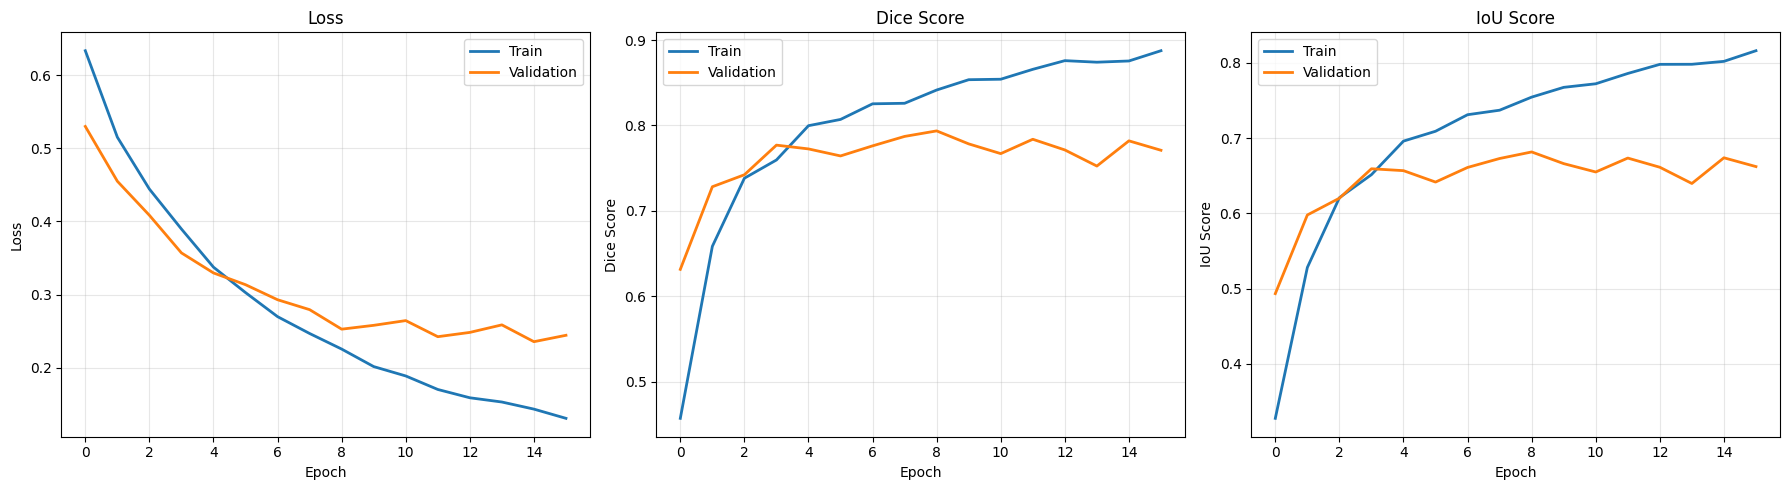

In [177]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

metrics = [
    ("loss", "Loss"),
    ("dice", "Dice Score"),
    ("iou", "IoU Score")
]

for ax, (metric, title) in zip(axes, metrics):

    ax.plot(
        history[f"train_{metric}"],
        label="Train",
        linewidth=2
    )

    ax.plot(
        history[f"val_{metric}"],
        label="Validation",
        linewidth=2
    )

    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel(title)
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [178]:
checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=DEVICE,
    weights_only=True
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model.eval()

print("Best Model Loaded!")
print("Best Validation Dice:", checkpoint["best_dice"])

Best Model Loaded!
Best Validation Dice: 0.793591296672821


In [179]:
test_metrics = run_epoch(
    model,
    val_loader,
    criterion
)

print("\nFinal Test Results")
print("-" * 30)

print(f"Test Loss : {test_metrics['loss']:.4f}")
print(f"Test Dice : {test_metrics['dice']:.4f}")
print(f"Test IoU  : {test_metrics['iou']:.4f}")

Validation:   0%|          | 0/4 [00:00<?, ?it/s]


Final Test Results
------------------------------
Test Loss : 0.3432
Test Dice : 0.6875
Test IoU  : 0.5567


In [180]:

def visualize_predictions(model, dataset, n=5, threshold=0.5):

    model.eval()

    indices = random.sample(
        range(len(dataset)),
        min(n, len(dataset))
    )

    fig, axes = plt.subplots(
        len(indices), 4,
        figsize=(16, 4 * len(indices)),
        squeeze=False
    )

    for i, idx in enumerate(indices):

        image, mask = dataset[idx]

        # Model Prediction
        with torch.inference_mode():
            logits = model(image.unsqueeze(0).to(DEVICE))
            probs = torch.sigmoid(logits)
            pred = (probs > threshold).float()

        pred = pred.squeeze().cpu().numpy()
        mask = mask.squeeze().cpu().numpy()

        # Original RGB Image
        img = image.permute(1, 2, 0).cpu().numpy()
        img = np.clip(img, 0, 1)

        # Calculate Dice Score
        intersection = (pred * mask).sum()

        dice = (2 * intersection + 1e-7) / (
            pred.sum() + mask.sum() + 1e-7
        )

        # Original Road Image
        axes[i, 0].imshow(img)
        axes[i, 0].set_title("Original Road Image")

        # Ground Truth
        axes[i, 1].imshow(mask, cmap="gray", vmin=0, vmax=1)
        axes[i, 1].set_title("Ground Truth")

        # Predicted Mask
        axes[i, 2].imshow(pred, cmap="gray", vmin=0, vmax=1)
        axes[i, 2].set_title(f"Prediction | Dice: {dice:.3f}")

        # Prediction Overlay
        axes[i, 3].imshow(img)
        axes[i, 3].imshow(
            np.ma.masked_where(pred == 0, pred),
            cmap="Reds",
            alpha=0.5,
            vmin=0,
            vmax=1
        )
        axes[i, 3].set_title("Pothole Detection Overlay")

        for ax in axes[i]:
            ax.axis("off")

    plt.tight_layout()
    plt.show()


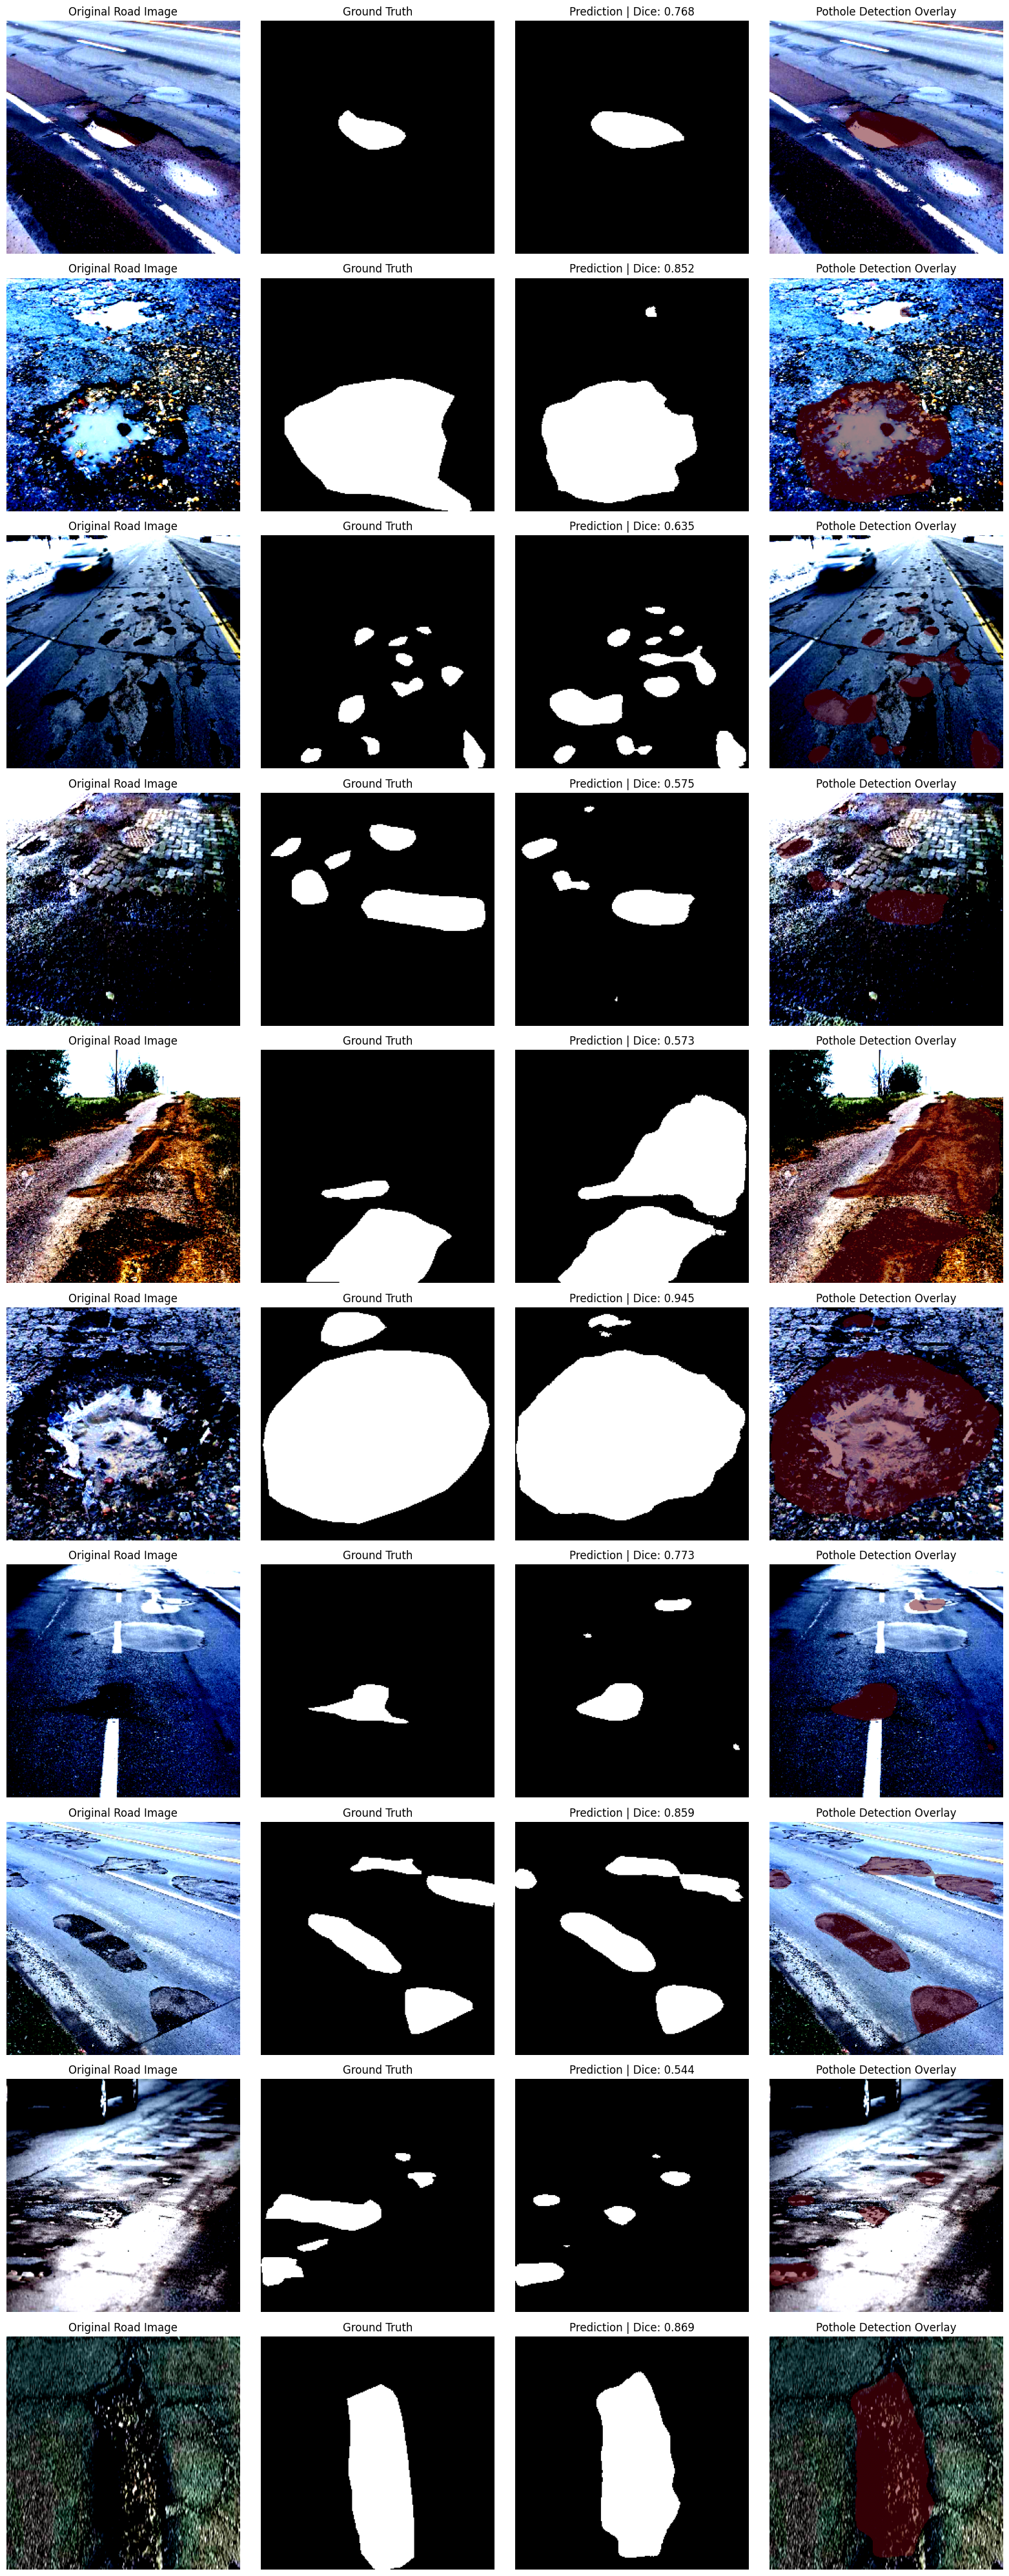

In [181]:
visualize_predictions(
    model=model,
    dataset=valid_dataset,
    n=10,
    threshold=0.5
)